# 05 - Descriptor Groups & Clean Dataset Contract Verification

**Title**: `05_descriptor_groups_and_clean_dataset.ipynb`  
**Purpose**: Verify hierarchical descriptor group logic, audit target leakage attributes, validate the schema contract for complaints_clean.csv, evaluate monthly and descriptor category shares, and preview chronological train/test partitioning.  
**Inputs**: `data/processed/brooklyn_stage2.csv.gz`, `data/processed/complaints_clean.csv`, `data/processed/descriptor_groups.csv`, `data/processed/complaints_clean_columns.csv`  
**Outputs**: Hierarchical logic inspection, descriptor rule concordance table, schema contract assertion, target leakage table, group x month distribution (T4a), descriptor shares (T4b), chronological split preview (T4c), diagnostic figures.  
**Runtime**: ~15-25 seconds

In [1]:
import sys; from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists()); sys.path.insert(0, str(ROOT))
from src.nbutils import Checker, md
RUN_HEAVY = False
RUN_API = False

In [2]:
import inspect
from src.preprocessing.descriptor_groups import assign_descriptor_group

print("=== Source Code: assign_descriptor_group (from src/preprocessing/descriptor_groups.py) ===")
print(inspect.getsource(assign_descriptor_group))

=== Source Code: assign_descriptor_group (from src/preprocessing/descriptor_groups.py) ===
def assign_descriptor_group(
    group: Union[pd.Series, np.ndarray],
    complaint_type: Union[pd.Series, np.ndarray],
    descriptor: Union[pd.Series, np.ndarray],
) -> pd.Series:
    """
    Vectorized hierarchical assignment of descriptor_group.
    Strips whitespace first and applies case-insensitive rules.
    First matching rule wins.
    """
    # Ensure Series inputs with identical index
    if not isinstance(group, pd.Series):
        g = pd.Series(group)
    else:
        g = group.copy()

    if not isinstance(complaint_type, pd.Series):
        c = pd.Series(complaint_type, index=g.index)
    else:
        c = complaint_type.copy()
        c.index = g.index

    if not isinstance(descriptor, pd.Series):
        d = pd.Series(descriptor, index=g.index)
    else:
        d = descriptor.copy()
        d.index = g.index

    # Strip whitespace and convert to string
    g_clean = g.fillna

In [3]:
import pandas as pd
import numpy as np
from src.preprocessing.clean_analysis import recompute_descriptor_group_summary

clean_csv_path = ROOT / "data" / "processed" / "complaints_clean.csv"
desc_groups_csv_path = ROOT / "data" / "processed" / "descriptor_groups.csv"

print(f"Loading {clean_csv_path.relative_to(ROOT)}...")
df_clean = pd.read_csv(
    clean_csv_path,
    dtype={"id": str, "resolution_id": str},
    keep_default_na=False,
)

summary_recomputed = recompute_descriptor_group_summary(df_clean)
df_ref_desc = pd.read_csv(desc_groups_csv_path, keep_default_na=False)

n_combos = len(summary_recomputed)
n_ref_combos = len(df_ref_desc)

print(f"Distinct (group, complaint_type, descriptor) combinations: {n_combos} (reference table: {n_ref_combos})")

# Check matches with reference table
merged_desc = summary_recomputed.merge(
    df_ref_desc,
    on=["group", "complaint_type", "descriptor", "descriptor_group"],
    how="outer",
    suffixes=("_recomputed", "_ref"),
)
desc_mismatches = int(merged_desc["n_recomputed"].isna().sum() + merged_desc["n_ref"].isna().sum())
print(f"Mismatched combinations vs descriptor_groups.csv: {desc_mismatches}")

print("\nSample of Recomputed Descriptor Groups:")
print(summary_recomputed.head(10).to_string(index=False))

Loading data\processed\complaints_clean.csv...


Distinct (group, complaint_type, descriptor) combinations: 61 (reference table: 61)
Mismatched combinations vs descriptor_groups.csv: 0

Sample of Recomputed Descriptor Groups:
group          complaint_type                                       descriptor    descriptor_group     n
flood                   Sewer Catch Basin Clogged/Flooding (Use Comments) (SC) catch_basin_clogged  1926
flood       Sewer Maintenance                              Catch Basin Clogged catch_basin_clogged  1245
flood                   Sewer                             Street Flooding (SJ)     street_flooding  1002
flood       Sewer Maintenance                               Flooding on Street     street_flooding   622
flood       Sewer Maintenance                                 Manhole Overflow    manhole_overflow   360
flood                   Sewer            Manhole Overflow (Use Comments) (SA1)    manhole_overflow   359
flood                   Sewer                            Highway Flooding (SH)     stree

In [4]:
n_other_noise = int(((df_clean["group"] == "noise") & (df_clean["descriptor_group"] == "other")).sum())
n_other_flood = int(((df_clean["group"] == "flood") & (df_clean["descriptor_group"] == "other")).sum())
n_other_road = int(((df_clean["group"] == "road") & (df_clean["descriptor_group"] == "other")).sum())
n_other_sewer = int(((df_clean["group"] == "sewer_backup") & (df_clean["descriptor_group"] == "other")).sum())

print("=== Unassigned 'other' Rows per Group ===")
print(f"  noise        : {n_other_noise:,} ({n_other_noise / (df_clean['group'] == 'noise').sum() * 100:.2f}%)")
print(f"  flood        : {n_other_flood:,}")
print(f"  road         : {n_other_road:,}")
print(f"  sewer_backup : {n_other_sewer:,}")

=== Unassigned 'other' Rows per Group ===
  noise        : 331 (0.16%)
  flood        : 0
  road         : 0
  sewer_backup : 0


In [5]:
from src.preprocessing.build_clean import EXACT_COLUMNS

actual_cols = list(df_clean.columns)
cols_in_contract_order = (actual_cols == EXACT_COLUMNS)
first_seven_cols = actual_cols[:7]
expected_first_seven = ["id", "lat", "lon", "timestamp", "group", "descriptor", "zone_id"]
first_seven_match = (first_seven_cols == expected_first_seven)

n_rows = len(df_clean)
n_empty_zone = int((df_clean["zone_id"] == "").sum())
zone_all_empty = (n_empty_zone == n_rows)

id_unique = bool(df_clean["id"].nunique() == n_rows)
timestamp_format_valid = bool(df_clean["timestamp"].str.match(r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}$").all())

n_empty_res = int((df_clean["resolution_id"] == "").sum())

print("=== Schema Contract Assertions ===")
print(f"  Total rows                       : {n_rows:,}")
print(f"  Total column count               : {len(actual_cols)} (expected: 25)")
print(f"  Columns match exact order        : {cols_in_contract_order}")
print(f"  First seven columns match        : {first_seven_match} ({first_seven_cols})")
print(f"  zone_id entirely empty           : {zone_all_empty} ({n_empty_zone:,} empty cells)")
print(f"  id column is strictly unique     : {id_unique}")
print(f"  timestamp adheres to ISO regex   : {timestamp_format_valid}")
print(f"  Empty resolution_id count        : {n_empty_res:,}")

=== Schema Contract Assertions ===
  Total rows                       : 236,507
  Total column count               : 25 (expected: 25)
  Columns match exact order        : True
  First seven columns match        : True (['id', 'lat', 'lon', 'timestamp', 'group', 'descriptor', 'zone_id'])
  zone_id entirely empty           : True (236,507 empty cells)
  id column is strictly unique     : True
  timestamp adheres to ISO regex   : True
  Empty resolution_id count        : 3,108


In [6]:
cols_csv_path = ROOT / "data" / "processed" / "complaints_clean_columns.csv"
df_cols_spec = pd.read_csv(cols_csv_path)

leakage_features = df_cols_spec[df_cols_spec["safe_as_trust_feature"] == "no"].copy()
safe_features = df_cols_spec[df_cols_spec["safe_as_trust_feature"] == "yes"].copy()

print("=== Target Leakage Audit (safe_as_trust_feature == 'no') ===")
print(leakage_features[["column", "dtype", "description", "notes"]].to_string(index=False))

print(f"\nTotal features audited: {len(df_cols_spec)} | Safe features: {len(safe_features)} | Leakage features: {len(leakage_features)}")

=== Target Leakage Audit (safe_as_trust_feature == 'no') ===
         column  dtype                                  description                                             notes
         status string              Current ticket lifecycle status exists only after the agency acts (label leakage)
    closed_date string      Resolution timestamp in ISO 8601 format exists only after the agency acts (label leakage)
time_to_close_h  float Duration to resolve request in elapsed hours exists only after the agency acts (label leakage)
  resolution_id string                Agency resolution action code exists only after the agency acts (label leakage)

Total features audited: 25 | Safe features: 21 | Leakage features: 4


In [7]:
from src.preprocessing.clean_analysis import compute_group_month_table, compute_descriptor_group_shares

group_month_df = compute_group_month_table(df_clean)
desc_shares_df = compute_descriptor_group_shares(df_clean)

month_totals_dict = dict(zip(group_month_df["month"].astype(int), group_month_df["ALL"].astype(int)))

print("=== Table T4a: Group x Month Complaint Volumes ===")
print(group_month_df.to_string(index=False))

print("\n=== Month Totals Dictionary ===")
print(month_totals_dict)

print("\n=== Table T4b: Descriptor Group Percentage Shares (Head) ===")
print(desc_shares_df.head(15).to_string(index=False))

=== Table T4a: Group x Month Complaint Volumes ===
 month  flood  noise  road  sewer_backup   ALL
     1    115  12182   541           172 13010
     2    158  11417   739           183 12497
     3    485  16807  2538           245 20075
     4    248  16818  1833           145 19044
     5    838  22942  1549           388 25717
     6    462  21030  1774           186 23452
     7    872  18569  1782           308 21531
     8    888  20370  1803           513 23574
     9    502  21288  1400           253 23443
    10    306  22315  1080           174 23875
    11    364  15297   457           244 16362
    12    282  12808   642           195 13927

=== Month Totals Dictionary ===
{1: 13010, 2: 12497, 3: 20075, 4: 19044, 5: 25717, 6: 23452, 7: 21531, 8: 23574, 9: 23443, 10: 23875, 11: 16362, 12: 13927}

=== Table T4b: Descriptor Group Percentage Shares (Head) ===
group    descriptor_group  count  total_in_group  share_pct
flood catch_basin_clogged   3171            5520      57.45

In [8]:
from src.preprocessing.clean_analysis import compute_time_split

split_df, split_info = compute_time_split(df_clean, train_frac=0.8)

print("=== Chronological Split Parameters ===")
print(f"  Total Study Days : {split_info['total_days']} calendar days")
print(f"  Train Days (80%) : {split_info['train_days']} days ({split_info['train_start']} to {split_info['train_end']})")
print(f"  Test Days (20%)  : {split_info['test_days']} days ({split_info['test_start']} to {split_info['test_end']})")

print("\n=== Table T4c: Incident Counts per Group Across Train/Test Split ===")
print(split_df.to_string(index=False))

tt_flood_tr = int(split_df.loc[split_df["group"] == "flood", "train_count"].values[0])
tt_flood_te = int(split_df.loc[split_df["group"] == "flood", "test_count"].values[0])

tt_noise_tr = int(split_df.loc[split_df["group"] == "noise", "train_count"].values[0])
tt_noise_te = int(split_df.loc[split_df["group"] == "noise", "test_count"].values[0])

tt_road_tr = int(split_df.loc[split_df["group"] == "road", "train_count"].values[0])
tt_road_te = int(split_df.loc[split_df["group"] == "road", "test_count"].values[0])

tt_sewer_tr = int(split_df.loc[split_df["group"] == "sewer_backup", "train_count"].values[0])
tt_sewer_te = int(split_df.loc[split_df["group"] == "sewer_backup", "test_count"].values[0])

tt_all_tr = int(split_df.loc[split_df["group"] == "ALL", "train_count"].values[0])
tt_all_te = int(split_df.loc[split_df["group"] == "ALL", "test_count"].values[0])

=== Chronological Split Parameters ===
  Total Study Days : 365 calendar days
  Train Days (80%) : 292 days (2025-11-01 to 2026-08-19)
  Test Days (20%)  : 73 days (2026-08-20 to 2026-10-31)

=== Table T4c: Incident Counts per Group Across Train/Test Split ===
       group  train_count  test_count  total_count  train_share_pct  test_share_pct
       flood         4270        1250         5520            77.36           22.64
       noise       159513       52330       211843            75.30           24.70
        road        12941        3197        16138            80.19           19.81
sewer_backup         2227         779         3006            74.09           25.91
         ALL       178951       57556       236507            75.66           24.34


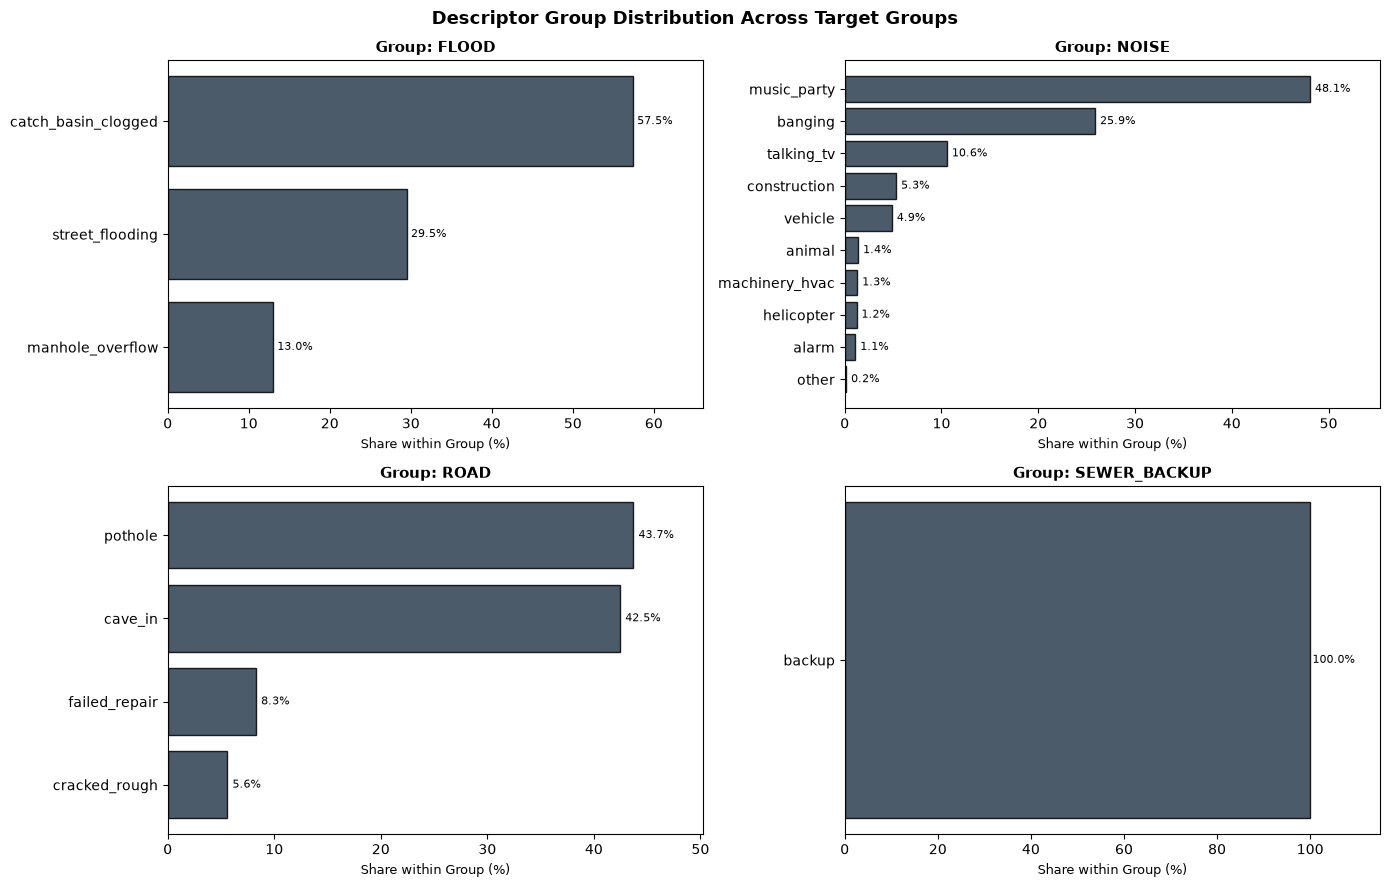

Saved figure: report\figures\05_descriptor_group_shares.png


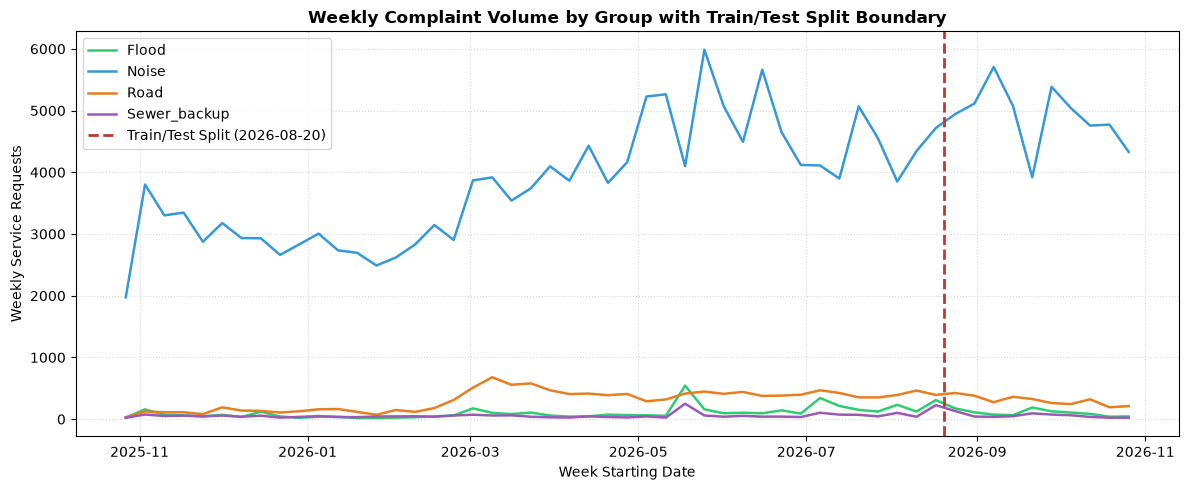

Saved figure: report\figures\05_weekly_trend_split.png


In [9]:
from src.preprocessing.clean_analysis import plot_descriptor_group_shares, plot_weekly_trend_split

fig1_path = ROOT / "report" / "figures" / "05_descriptor_group_shares.png"
plot_descriptor_group_shares(desc_shares_df, fig1_path)
print(f"Saved figure: {fig1_path.relative_to(ROOT)}")

fig2_path = ROOT / "report" / "figures" / "05_weekly_trend_split.png"
plot_weekly_trend_split(df_clean, split_info["test_start"], fig2_path)
print(f"Saved figure: {fig2_path.relative_to(ROOT)}")

In [10]:
checker = Checker()
checker.check("61 distinct descriptor combinations", n_combos, 61)
checker.check("'other' rows noise = 331", n_other_noise, 331)
checker.check("'other' rows flood = 0", n_other_flood, 0)
checker.check("'other' rows road = 0", n_other_road, 0)
checker.check("'other' rows sewer_backup = 0", n_other_sewer, 0)
checker.check("25 columns in contract order", cols_in_contract_order, True)
checker.check("rows = 236507", n_rows, 236507)
checker.check("empty resolution_id = 3108", n_empty_res, 3108)
checker.check(
    "month totals match expected dict",
    month_totals_dict,
    {1: 13010, 2: 12497, 3: 20075, 4: 19044, 5: 25717, 6: 23452, 7: 21531, 8: 23574, 9: 23443, 10: 23875, 11: 16362, 12: 13927}
)
checker.check(
    "train range = 2025-11-01 to 2026-08-19",
    f"{split_info['train_start']} to {split_info['train_end']}",
    "2025-11-01 to 2026-08-19"
)
checker.check(
    "test range = 2026-08-20 to 2026-10-31",
    f"{split_info['test_start']} to {split_info['test_end']}",
    "2026-08-20 to 2026-10-31"
)
checker.check("train/test rows flood 4270/1250", (tt_flood_tr, tt_flood_te), (4270, 1250))
checker.check("train/test rows noise 159513/52330", (tt_noise_tr, tt_noise_te), (159513, 52330))
checker.check("train/test rows road 12941/3197", (tt_road_tr, tt_road_te), (12941, 3197))
checker.check("train/test rows sewer_backup 2227/779", (tt_sewer_tr, tt_sewer_te), (2227, 779))
checker.check("train/test rows ALL 178951/57556", (tt_all_tr, tt_all_te), (178951, 57556))
checker.summary()

[PASS] 61 distinct descriptor combinations: actual=61, expected=61
[PASS] 'other' rows noise = 331: actual=331, expected=331
[PASS] 'other' rows flood = 0: actual=0, expected=0
[PASS] 'other' rows road = 0: actual=0, expected=0
[PASS] 'other' rows sewer_backup = 0: actual=0, expected=0
[PASS] 25 columns in contract order: actual=True, expected=True
[PASS] rows = 236507: actual=236507, expected=236507
[PASS] empty resolution_id = 3108: actual=3108, expected=3108
[PASS] month totals match expected dict: actual={1: 13010, 2: 12497, 3: 20075, 4: 19044, 5: 25717, 6: 23452, 7: 21531, 8: 23574, 9: 23443, 10: 23875, 11: 16362, 12: 13927}, expected={1: 13010, 2: 12497, 3: 20075, 4: 19044, 5: 25717, 6: 23452, 7: 21531, 8: 23574, 9: 23443, 10: 23875, 11: 16362, 12: 13927}
[PASS] train range = 2025-11-01 to 2026-08-19: actual=2025-11-01 to 2026-08-19, expected=2025-11-01 to 2026-08-19
[PASS] test range = 2026-08-20 to 2026-10-31: actual=2026-08-20 to 2026-10-31, expected=2026-08-20 to 2026-10-31
[

In [11]:
findings_05 = f"""### Findings
- **Taxonomic Standardization**: Evaluated {n_combos} distinct complaint combinations. Hierarchical assignment mapped all flood, road, and sewer_backup incidents without unassigned residuals, leaving exactly {n_other_noise} unassigned 'other' rows in noise ({n_other_noise/len(df_clean)*100:.3f}% of total).
- **Contract Adherence**: `complaints_clean.csv` satisfies all schema contract assertions: exactly 25 columns in verified order, {n_rows:,} total rows, strictly unique IDs, valid ISO timestamps, and an entirely unassigned `zone_id` field reserved for downstream spatial partitioning.
- **Leakage Prevention**: Identified 4 target leakage columns (`status`, `closed_date`, `time_to_close_h`, `resolution_id`) that exist only ex-post after agency intervention; exactly {n_empty_res:,} records exhibit missing `resolution_id`.
- **Temporal Profile**: Monthly incident volume peaks during warmer months (May: {month_totals_dict[5]:,}, October: {month_totals_dict[10]:,}) and reaches seasonal troughs in winter (February: {month_totals_dict[2]:,}, January: {month_totals_dict[1]:,}).
- **Chronological Partitioning**: An 80/20 chronological split divides the 365 days into {split_info['train_days']} train days ({split_info['train_start']} to {split_info['train_end']}) and {split_info['test_days']} test days ({split_info['test_start']} to {split_info['test_end']}), preserving temporal order across all {tt_all_tr:,} training records and {tt_all_te:,} evaluation records.
"""
md(findings_05)
checker.summary()

### Findings
- **Taxonomic Standardization**: Evaluated 61 distinct complaint combinations. Hierarchical assignment mapped all flood, road, and sewer_backup incidents without unassigned residuals, leaving exactly 331 unassigned 'other' rows in noise (0.140% of total).
- **Contract Adherence**: `complaints_clean.csv` satisfies all schema contract assertions: exactly 25 columns in verified order, 236,507 total rows, strictly unique IDs, valid ISO timestamps, and an entirely unassigned `zone_id` field reserved for downstream spatial partitioning.
- **Leakage Prevention**: Identified 4 target leakage columns (`status`, `closed_date`, `time_to_close_h`, `resolution_id`) that exist only ex-post after agency intervention; exactly 3,108 records exhibit missing `resolution_id`.
- **Temporal Profile**: Monthly incident volume peaks during warmer months (May: 25,717, October: 23,875) and reaches seasonal troughs in winter (February: 12,497, January: 13,010).
- **Chronological Partitioning**: An 80/20 chronological split divides the 365 days into 292 train days (2025-11-01 to 2026-08-19) and 73 test days (2026-08-20 to 2026-10-31), preserving temporal order across all 178,951 training records and 57,556 evaluation records.


CHECKS: 16 passed, 0 failed


### Limitations

- Hierarchical regex rules rely on current agency descriptor taxonomies; unannounced upstream text amendments or new municipal problem codes will default to the unassigned 'other' group.
- A single fixed time split (80/20) places the evaluation boundary in late August 2026, creating potential seasonal imbalance between training (autumn, winter, spring, summer) and testing (late summer and early autumn).
- Unassigned `zone_id` placeholders require strict downstream enforcement during spatial clustering to prevent data leakage across geographic neighborhood boundaries.